# Shipping Cost Prediction: End-to-End Baseline ML Model (MLOps)

This notebook builds a complete machine learning project **from start to finish**: from the business problem to a saved model that predicts the cost of new shipments.

It is intentionally **simple**. The goal is not the most accurate model possible. The goal is a clean, reproducible baseline that we can later turn into a production pipeline (modular code, tests, CI/CD, API, monitoring) during the MLOps course.

> Simplified from the notebook *Regression_Improve Bagg & RF with Boosting*.

## 0. Business Case: Predicting the Cost of Logistics Services

### Context
A logistics company (freight forwarder) moves its customers' cargo by **road, sea and air**. Every time a customer asks for a quote, the commercial team must first estimate **how much the service will cost the company** (carrier rates, fuel, handling, surcharges). Only then can they add a margin and send a selling price.

Today this estimate is built **manually** from carrier tariff tables, spreadsheets and the experience of each sales rep.

### The problem
| Pain point | Business impact |
|---|---|
| **Slow:** a quote can take hours or days | Customers go to faster competitors and deals are lost |
| **Inconsistent:** two reps can price the same shipment differently | Unclear pricing policy, hard to audit |
| **Risky:** errors in the cost estimate | Underestimating erodes the margin; overestimating loses the deal |

### Proposed solution
A machine learning model that takes the basic shipment details known **at quotation time** (transport mode, cargo type, distance, weight, volume, urgency and month) and returns the **expected cost in USD** in a fraction of a second. The sales team uses this number as a **reference cost** and adds their margin on top of it.

### ML framing
| Item | Definition |
|---|---|
| **Problem type** | Supervised learning, **regression** (we predict a continuous number) |
| **Unit of prediction** | One shipment |
| **Target (y)** | `cost_usd`: total cost of the shipment in USD |
| **Features (X)** | `transport_mode`, `cargo_type`, `distance_km`, `weight_kg`, `volume_m3`, `urgent`, `month` |
| **Key rule** | Only use information **available when quoting** (no data that is only known after the shipment, which would cause *data leakage*) |
| **End users** | Sales / pricing team |

### Success metrics
- **Model metric (main): MAE (Mean Absolute Error) in USD.** It measures by how many dollars the estimate misses on average, so the business can read it directly.
- **Secondary metrics:** RMSE (penalizes large misses more) and R² (share of the cost variability the model explains).
- **Minimum bar:** the model must clearly beat a **naive baseline** (always predicting the median cost). Our target is to **cut the baseline error by at least 50%**.
- **Business KPIs (after deployment):** quote turnaround time, quote win rate, and the gap between estimated cost and the cost actually invoiced by carriers.

### Data
The project uses **one single dataset**, `data/shipments.xlsx` (5,000 shipments), described in section 2. It is the only data source for training and evaluation.

### Out of scope (for this version)
Setting the selling price or margin, live carrier rates, and route optimization.

### Notebook workflow

Each section of this notebook will later become a module of the MLOps project (`MLOPS-project/src/`):

| # | Section | What it does | Future module |
|---|---|---|---|
| 1 | Setup | Imports, paths and parameters in one place | `config.yaml` |
| 2 | Data source | Define the single dataset used by the project | data source (`data/raw/`) |
| 3 | Load and validate data | Read the Excel file and run a data quality gate | `load_data.py`, `validate.py` |
| 4 | Exploratory data analysis | Understand the target and its main drivers | notebooks only |
| 5 | Train / test split | Hold out unseen data for a fair evaluation | `main.py` |
| 6 | Baseline | Minimum reference every model must beat | `evaluate.py` |
| 7 | Model training | Preprocessing and model in one pipeline, tuned with cross-validation | `features.py`, `train.py` |
| 8 | Evaluation and model selection | Compare models on the test set and pick the best one | `evaluate.py` |
| 9 | Feature importance | Explain which variables drive the predictions | `evaluate.py` / `reports/` |
| 10 | Save the model | Persist the model and its metadata (artifact) | `train.py`, `utils.py` |
| 11 | Inference | Load the artifact and predict new shipments | `infer.py` |
| 12 | Conclusions and next steps | Results, limitations and MLOps roadmap | `README.md` |

## 1. Setup

We import the libraries used in the project:
- **pandas / numpy:** data handling.
- **scikit-learn:** preprocessing, pipeline, Random Forest, hyperparameter search and metrics.
- **LightGBM:** gradient boosting model, the second candidate.
- **matplotlib:** plots.
- **joblib:** saving and loading the trained model.
- **openpyxl:** pandas uses it under the hood to read and write Excel files.

In [1]:
# Install dependencies (run once if needed)
# !pip install pandas numpy scikit-learn lightgbm openpyxl matplotlib joblib

import json
import time
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import warnings
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:.2f}'.format

All paths and parameters are defined **in one single place**. This is an MLOps best practice: nothing is hardcoded across the notebook, so changing the data file, the target or the seed only requires editing this cell. Later on, these values will move to `config.yaml`.

- `DATA_PATH` points to the project's single dataset (see section 2).
- `RANDOM_STATE` fixes the randomness (split and models), so anyone who runs the notebook gets **the same results** (reproducibility).
- `NUM_FEATURES` and `CAT_FEATURES` separate numeric and categorical variables, because they are preprocessed differently.

In [2]:
RANDOM_STATE = 42      # fixed seed -> reproducible results
TEST_SIZE = 0.2        # share of data held out for the final evaluation

DATA_DIR = Path('data')
MODEL_DIR = Path('models')
OUTPUT_DIR = Path('outputs')
for d in (MODEL_DIR, OUTPUT_DIR):
    d.mkdir(exist_ok=True)

DATA_PATH = DATA_DIR / 'shipments.xlsx'   # single source of data for the project
MODEL_PATH = MODEL_DIR / 'shipping_cost_model.joblib'
METRICS_PATH = MODEL_DIR / 'metrics.json'
PREDICTIONS_PATH = OUTPUT_DIR / 'predictions.xlsx'

TARGET = 'cost_usd'
NUM_FEATURES = ['distance_km', 'weight_kg', 'volume_m3', 'urgent', 'month']
CAT_FEATURES = ['transport_mode', 'cargo_type']
FEATURES = NUM_FEATURES + CAT_FEATURES

## 2. Data Source

The project works with **one single, fixed dataset**, defined from the start:

| Item | Value |
|---|---|
| **File** | `data/shipments.xlsx` |
| **Data sheet** | `data`: 5,000 shipments, one row per shipment |
| **Documentation sheet** | `data_dictionary`: description of every column |
| **Columns** | `shipment_id`, `transport_mode`, `cargo_type`, `distance_km`, `weight_kg`, `volume_m3`, `urgent`, `month`, `cost_usd` (target) |

The notebook **never creates or modifies** this file: it only reads it. This keeps the data **fixed and versionable**, so every run trains on exactly the same data and results are reproducible. Later in the MLOps project this file lives in `data/raw/` and is versioned (e.g. with DVC).

## 3. Load and Validate the Data

We read the dataset defined in section 2. If the file is missing, the notebook stops with a clear message instead of failing later.

In [3]:
assert DATA_PATH.exists(), f'Dataset not found: {DATA_PATH}'

df = pd.read_excel(DATA_PATH, sheet_name='data')
print(df.shape)
df.head()

(5000, 9)


,shipment_id,transport_mode,cargo_type,distance_km,weight_kg,volume_m3,urgent,month,cost_usd
0,1,Sea,General,8928.00,1683.20,4.72,0,3,1077.16
1,2,Road,General,1792.50,2354.90,11.75,1,12,1855.53
2,3,Air,Refrigerated,2266.10,561.40,1.45,1,8,1818.41
3,4,Sea,General,1403.20,118.20,0.39,1,11,493.24
4,5,Road,General,794.30,2374.50,7.26,1,8,545.76


The data dictionary stored in the same file documents what each column means:

In [4]:
pd.read_excel(DATA_PATH, sheet_name='data_dictionary')

,column,description
0,shipment_id,Shipment identifier
1,transport_mode,Road / Sea / Air
2,cargo_type,General / Refrigerated / Hazardous
3,distance_km,Origin-destination distance in km
4,weight_kg,Actual cargo weight in kg
5,volume_m3,Cargo volume in m3
6,urgent,"1 if the shipment is urgent, 0 otherwise"
7,month,Shipment month (1-12)
8,cost_usd,TARGET: shipment cost in USD


### Data quality gate
Before training we check that the data meets the minimum conditions. If any check fails, the notebook **stops with a clear message** instead of training a model on bad data. In production this check runs automatically every time new data arrives (`validate.py`).

We check that:
1. All the expected columns exist (schema).
2. There are no missing values.
3. The cost is always positive.
4. The categorical columns only contain known categories.

*Note:* the current dataset passes all checks, so we do not need a cleaning step. If new data arrives with duplicates, typos in categories or unit issues, a `clean_data.py` step would handle them.

In [5]:
expected_cols = set(FEATURES + [TARGET])
missing_cols = expected_cols - set(df.columns)
assert not missing_cols, f'Missing columns: {missing_cols}'
assert df[FEATURES + [TARGET]].isna().sum().sum() == 0, 'There are missing values'
assert (df[TARGET] > 0).all(), 'There are non-positive costs'
assert set(df['transport_mode']) <= {'Road', 'Sea', 'Air'}, 'Unknown transport_mode'
assert set(df['cargo_type']) <= {'General', 'Refrigerated', 'Hazardous'}, 'Unknown cargo_type'
print('Data validation OK')

Data validation OK


## 4. Exploratory Data Analysis (EDA)

A quick look to understand the target and its main drivers before modeling.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
shipment_id,5000.00,2500.50,1443.52,1.00,1250.75,2500.50,3750.25,5000.00
distance_km,5000.00,3131.31,3046.47,50.00,1010.90,1905.50,4557.02,11999.40
weight_kg,5000.00,681.16,807.75,10.00,209.40,414.55,827.80,9899.50
volume_m3,5000.00,3.16,4.44,0.03,0.85,1.77,3.72,93.21
urgent,5000.00,0.20,0.40,0.00,0.00,0.00,0.00,1.00
month,5000.00,6.49,3.46,1.00,3.00,6.00,9.00,12.00
cost_usd,5000.00,1033.97,3073.77,69.26,178.12,380.79,758.73,73579.03


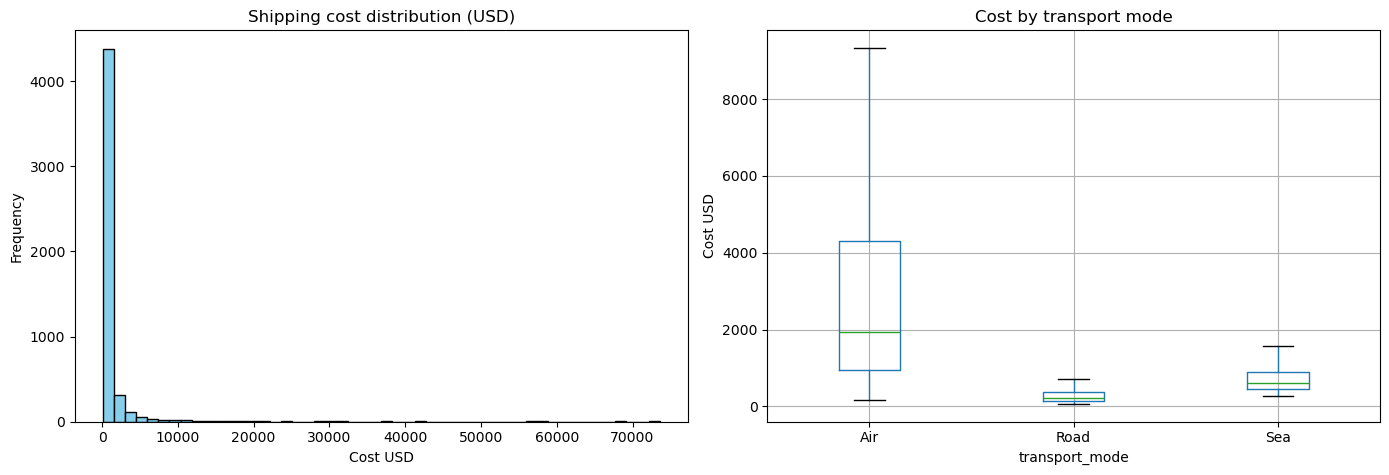

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df[TARGET].plot(kind='hist', bins=50, color='skyblue', edgecolor='black', ax=axes[0])
axes[0].set_title('Shipping cost distribution (USD)')
axes[0].set_xlabel('Cost USD')

df.boxplot(column=TARGET, by='transport_mode', ax=axes[1], showfliers=False)
axes[1].set_title('Cost by transport mode')
axes[1].set_ylabel('Cost USD')
plt.suptitle('')
plt.tight_layout()
plt.show()

**Key takeaways:**
- **The cost is heavily right-skewed.** The median shipment costs about **381 USD**, but the mean is about **1,034 USD** and the maximum exceeds **73,000 USD**. A few large shipments (mainly heavy air cargo) pull the average up. These extreme cases are the hardest to predict and will dominate RMSE.
- **Transport mode is the main driver of cost.** Median cost by mode: **Air ≈ 1,944 USD**, **Sea ≈ 612 USD**, **Road ≈ 209 USD**.
- **Distance and weight vary a lot** (from 50 km to 12,000 km and from 10 kg to almost 10 tons), so the model has to learn their interaction with the transport mode.
- Cargo type and urgency also raise the cost (e.g. median urgent ≈ 500 USD vs non-urgent ≈ 361 USD), but less than the transport mode.

## 5. Train / Test Split

We split the data into two parts **before fitting anything**:
- **Train (80%):** used to train and tune the models.
- **Test (20%):** kept aside and used **only once**, at the end, to estimate how the model will perform on shipments it has never seen.

Splitting first prevents *data leakage*: no information from the test set can influence training, so the final metric is an honest estimate.

*Note:* the course pipeline uses train / validation / test. Here we replace the separate validation set with **cross-validation on the train set** (section 7), which makes better use of the data.

In [8]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')

Train: (4000, 7)  |  Test: (1000, 7)


## 6. Baseline: Always Predict the Median

Before training any ML model we need a **reference point**. The simplest "model" ignores every feature and always predicts the **median cost of the training set**.

This answers a key business question: *is ML worth it?* Any model we train must **clearly beat this error**. Otherwise its extra complexity is not justified.

In [9]:
baseline_pred = np.full(len(y_test), y_train.median())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
print(f'Baseline MAE (median): {baseline_mae:,.2f} USD')

Baseline MAE (median): 843.27 USD


Always quoting the median would be off by about **843 USD per shipment** on average. That is a very large error considering that the typical shipment costs about 381 USD.

## 7. Model Training

### 7.1 Preprocessing + model in one Pipeline
We use a scikit-learn **Pipeline**, which chains preprocessing and the model into **a single object**:
- **Categorical variables** (`transport_mode`, `cargo_type`) are converted to numbers with **One-Hot Encoding** (one 0/1 column per category). `handle_unknown='ignore'` keeps the model from failing if a new category ever appears.
- **Numeric variables** pass through unchanged (`passthrough`). Tree-based models do not need scaling.

**Why does this matter for MLOps?** The saved artifact receives **raw data** (just like the Excel file) and performs all the transformations internally. Whoever uses the model in production does not have to repeat the preprocessing, which avoids differences between training and production (*training-serving skew*).

In [10]:
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
    ('num', 'passthrough', NUM_FEATURES),
])

def make_pipeline(model):
    return Pipeline([('prep', preprocessor), ('model', model)])

### 7.2 Candidate models and hyperparameter search
We compare two tree ensembles. Both handle non-linear relationships and interactions (e.g. *distance × weight × mode*) well:

| Model | Idea | Strength |
|---|---|---|
| **Random Forest** (*bagging*) | Trains many independent trees on random samples of the data and averages them | Robust, few hyperparameters, hard to overfit |
| **LightGBM** (*boosting*) | Trains trees **sequentially**, each one correcting the errors of the previous ones | Usually very accurate and fast |

To pick the hyperparameters we use **GridSearchCV** with **3-fold cross-validation** on the training set only: the train set is split into 3 parts, and each combination is trained on 2 and evaluated on the third, rotating. We optimize **MAE**, the business metric. The grid is kept small (8 combinations per model) so it runs in under a minute.

In [11]:
candidates = {
    'Random Forest': (
        make_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
        {
            'model__max_depth': [None, 10],
            'model__min_samples_leaf': [5, 20],
            'model__max_features': [0.5, 1.0],
        },
    ),
    'LightGBM': (
        make_pipeline(lgb.LGBMRegressor(n_estimators=500, random_state=RANDOM_STATE, verbosity=-1)),
        {
            'model__learning_rate': [0.03, 0.1],
            'model__num_leaves': [15, 31],
            'model__min_child_samples': [20, 50],
        },
    ),
}

searches = {}
for name, (pipe, grid) in candidates.items():
    start = time.time()
    search = GridSearchCV(pipe, grid, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f'{name}: CV MAE = {-search.best_score_:,.2f}  |  {time.time() - start:.0f}s  |  {search.best_params_}')

Random Forest: CV MAE = 228.18  |  17s  |  {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}
LightGBM: CV MAE = 257.75  |  42s  |  {'model__learning_rate': 0.03, 'model__min_child_samples': 20, 'model__num_leaves': 31}


## 8. Evaluation on the Test Set and Model Selection

We now evaluate the best version of each model on the **test set** (data never used during training or tuning), with three complementary metrics:

| Metric | Meaning | How to read it |
|---|---|---|
| **MAE** | Average absolute error in USD | "On average, the estimate misses by X dollars." Lower is better |
| **RMSE** | Square root of the mean squared error | Penalizes large errors more. If RMSE ≫ MAE, there are a few very large misses |
| **R²** | Share of the cost variability explained | 1 = perfect, 0 = same as predicting the mean. Higher is better |

We also show **Train MAE** and **CV MAE** to diagnose overfitting.

In [12]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

rows = {'Baseline (median)': regression_metrics(y_test, baseline_pred)}
for name, search in searches.items():
    model = search.best_estimator_
    test_m = regression_metrics(y_test, model.predict(X_test))
    test_m['Train MAE'] = mean_absolute_error(y_train, model.predict(X_train))
    test_m['CV MAE'] = -search.best_score_
    rows[name] = test_m

results = pd.DataFrame(rows).T
results

,MAE,RMSE,R2,Train MAE,CV MAE
Baseline (median),843.27,2978.44,-0.05,NaN,NaN
Random Forest,188.65,970.75,0.89,155.30,228.18
LightGBM,249.97,1069.30,0.86,137.12,257.75


**How to read the table:**
- **Both models clearly beat the baseline.** Their MAE is several times lower and R² goes from ≈ 0 to above 0.85.
- **Overfitting check:** if the *Train MAE* is much lower than the *CV / Test MAE*, the model memorizes the training data instead of generalizing. LightGBM shows a larger gap than Random Forest.
- **RMSE is much larger than MAE** for every model. As we saw in the EDA, a few very expensive shipments produce large errors in absolute dollars.

We select the model with the **lowest MAE on the test set**:

In [13]:
best_name = results.drop('Baseline (median)')['MAE'].idxmin()
best_model = searches[best_name].best_estimator_
improvement = 1 - results.loc[best_name, 'MAE'] / baseline_mae

print(f'Best model: {best_name}')
print(f'Test MAE: {results.loc[best_name, "MAE"]:,.2f} USD  ({improvement:.0%} better than the baseline)')

Best model: Random Forest
Test MAE: 188.65 USD  (78% better than the baseline)


### Actual vs. predicted cost
Each point is a test shipment. If the model were perfect, all the points would lie on the red diagonal line. Points above the line are **overestimated** shipments; points below are **underestimated**.

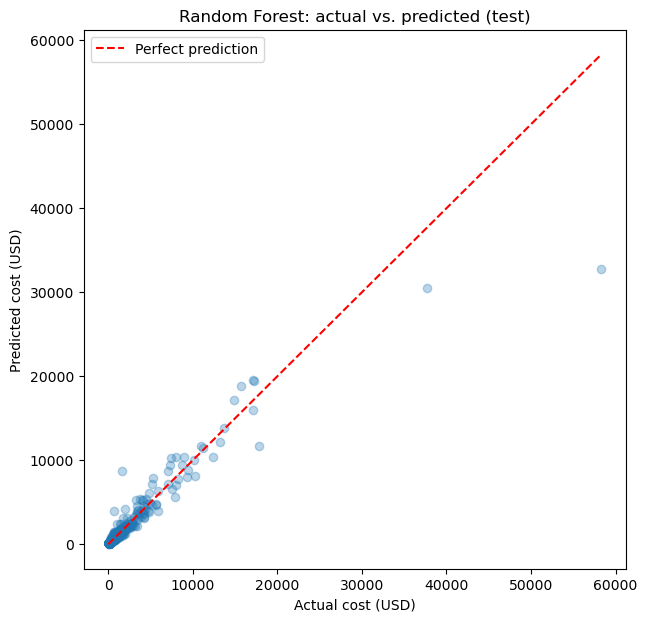

In [14]:
y_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.3)
lims = [0, max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual cost (USD)')
plt.ylabel('Predicted cost (USD)')
plt.title(f'{best_name}: actual vs. predicted (test)')
plt.legend()
plt.show()

## 9. Feature Importance

To trust the model (and explain it to the business) we need to know **which variables drive its predictions**.

We use **permutation importance**: we randomly shuffle one variable at a time in the test set and measure **how much the MAE gets worse**. If shuffling a variable increases the error a lot, the model depends heavily on it. Advantages:
- It works the same way for any model.
- It is expressed in the original columns and in USD, so it is easy to interpret.

**Sanity check:** the ranking should make business sense. Transport mode, distance and weight/volume should matter most, as they do in real carrier pricing.

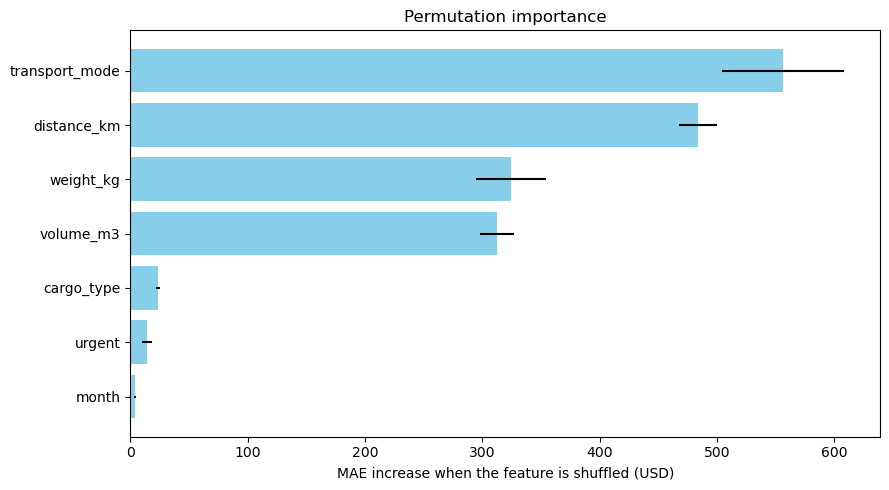

In [15]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, scoring='neg_mean_absolute_error', random_state=RANDOM_STATE
)

perm_imp = pd.DataFrame({
    'feature': FEATURES,
    'importance': perm.importances_mean,
    'std': perm.importances_std,
}).sort_values('importance')

plt.figure(figsize=(9, 5))
plt.barh(perm_imp['feature'], perm_imp['importance'], xerr=perm_imp['std'], color='skyblue')
plt.xlabel('MAE increase when the feature is shuffled (USD)')
plt.title('Permutation importance')
plt.tight_layout()
plt.show()

**Takeaways:** the ranking matches the business logic. **Transport mode** and **distance** are the strongest drivers, followed by **weight** and **volume** (together they make up the chargeable weight). **Cargo type**, **urgency** and **month** act as surcharges, so they have a much smaller effect on the error in USD. The model learned a pricing structure consistent with how carriers charge, purely from the data.

## 10. Save the Model (Artifact)

Once the best model and its hyperparameters are chosen, we **retrain it on all the data** (train + test). The test set has already done its job (giving an honest estimate of performance), and more data usually gives a slightly better model.

We save two files:
- **The model** (`shipping_cost_model.joblib`): the complete pipeline (preprocessing + model), ready to receive raw data.
- **Its metadata** (`metrics.json`): which model it is, with which hyperparameters, which data, when it was trained and its test metrics. This gives **traceability**, a key MLOps principle: for any model in production we can answer "where did it come from and how good is it?".

In [16]:
final_model = best_model.fit(X, y)
joblib.dump(final_model, MODEL_PATH)

metadata = {
    'model_name': best_name,
    'trained_at': pd.Timestamp.now().isoformat(timespec='seconds'),
    'data_path': str(DATA_PATH),
    'n_rows': len(df),
    'features': FEATURES,
    'target': TARGET,
    'best_params': searches[best_name].best_params_,
    'test_metrics': results.loc[best_name, ['MAE', 'RMSE', 'R2']].round(4).to_dict(),
    'baseline_mae': round(baseline_mae, 4),
}
with open(METRICS_PATH, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f'Model saved to {MODEL_PATH}')
print(json.dumps(metadata, indent=2, ensure_ascii=False))

Model saved to models\shipping_cost_model.joblib
{
  "model_name": "Random Forest",
  "trained_at": "2026-11-01T18:24:03",
  "data_path": "data\\shipments.xlsx",
  "n_rows": 5000,
  "features": [
    "distance_km",
    "weight_kg",
    "volume_m3",
    "urgent",
    "month",
    "transport_mode",
    "cargo_type"
  ],
  "target": "cost_usd",
  "best_params": {
    "model__max_depth": null,
    "model__max_features": 0.5,
    "model__min_samples_leaf": 5
  },
  "test_metrics": {
    "MAE": 188.6498,
    "RMSE": 970.75,
    "R2": 0.8886
  },
  "baseline_mae": 843.2749
}


## 11. Inference: Load the Model and Predict New Shipments

We simulate what a production service (e.g. a quoting API) would do: **load the saved artifact** and predict the cost of new shipments, **without retraining**. The input is just the raw shipment data, exactly as the sales team would enter it.

We test three typical quotes:
1. A domestic road shipment of general cargo.
2. An urgent air shipment of refrigerated cargo in peak season (December).
3. A long-distance sea shipment of heavy hazardous cargo.

In [17]:
loaded_model = joblib.load(MODEL_PATH)

new_shipments = pd.DataFrame([
    {'transport_mode': 'Road', 'cargo_type': 'General',      'distance_km': 900,  'weight_kg': 1200, 'volume_m3': 5.0,  'urgent': 0, 'month': 3},
    {'transport_mode': 'Air',  'cargo_type': 'Refrigerated', 'distance_km': 4500, 'weight_kg': 300,  'volume_m3': 2.5,  'urgent': 1, 'month': 12},
    {'transport_mode': 'Sea',  'cargo_type': 'Hazardous',    'distance_km': 9000, 'weight_kg': 8000, 'volume_m3': 30.0, 'urgent': 0, 'month': 6},
])

new_shipments['predicted_cost_usd'] = loaded_model.predict(new_shipments[FEATURES]).round(2)
new_shipments

,transport_mode,cargo_type,distance_km,weight_kg,volume_m3,urgent,month,predicted_cost_usd
0,Road,General,900,1200,5.00,0,3,327.31
1,Air,Refrigerated,4500,300,2.50,1,12,2105.92
2,Sea,Hazardous,9000,8000,30.00,0,6,11056.76


Finally, we export the results to Excel so the business team can review them:
- **`test` sheet:** each test shipment with its actual cost, predicted cost and absolute error, which is useful to analyze where the model fails most.
- **`new_shipments` sheet:** the predictions for the new quotes.

In [18]:
test_results = X_test.copy()
test_results['actual_cost_usd'] = y_test
test_results['predicted_cost_usd'] = y_pred.round(2)
test_results['abs_error_usd'] = (test_results['actual_cost_usd'] - test_results['predicted_cost_usd']).abs()

with pd.ExcelWriter(PREDICTIONS_PATH) as writer:
    test_results.to_excel(writer, sheet_name='test', index=False)
    new_shipments.to_excel(writer, sheet_name='new_shipments', index=False)

print(f'Predictions saved to {PREDICTIONS_PATH}')

Predictions saved to outputs\predictions.xlsx


## 12. Conclusions and Next Steps

### Conclusions
- We built an **end-to-end ML pipeline** for the business case: data → validation → EDA → split → baseline → training → evaluation → explainability → saved artifact → inference.
- The selected model **cuts the average estimation error by more than 75%** compared to the naive baseline, which **meets the success target (≥ 50%)** defined in the business case.
- The model can return a reference cost for any new quote in milliseconds, which addresses the speed and consistency problems of manual quoting.

### Limitations
- The model has only been trained and validated on this dataset (5,000 shipments). It must be re-validated whenever the dataset is updated.
- Errors on **very expensive shipments** (heavy air cargo) are large in absolute USD. Possible improvements: train on `log(cost)`, add the *chargeable weight* as an explicit feature, or use a percentage error metric (MAPE).
- Real costs depend on more factors (specific route, carrier, fuel prices, exchange rates) that are not in this dataset.

### Next steps (MLOps roadmap)
| Stage | What to do |
|---|---|
| **Modular code** | Move each section into `src/` modules (`load_data.py`, `validate.py`, `features.py`, `train.py`, `evaluate.py`, `infer.py`) orchestrated by `main.py` |
| **Configuration** | Move the parameters from section 1 to `config.yaml` |
| **Testing and CI** | Unit tests for validation and preprocessing; a GitHub Actions workflow that runs them on every push |
| **Experiment tracking** | Log parameters, metrics and models with MLflow |
| **Data and model versioning** | DVC and/or a model registry |
| **Serving** | A FastAPI service that loads `shipping_cost_model.joblib`, packaged with Docker |
| **Monitoring** | Detect *data drift* by comparing new shipments against the training data, and track the gap between predicted and invoiced costs |